# 02 — Changeup validation and home/road comparisons

**Research question.** Is the changeup movement difference larger than ordinary year-to-year variability, and is it present within pitchers' Rockies seasons at home versus on the road?

Starts with calendar-year-matched placebo comparisons using non-Rockies players, then evaluates Jon Gray, an exploratory transition cohort, and a separate usage-selected 2024 cohort. The 2024 sample produces the final pitcher-level bootstrap confidence interval.

**Requires:** files generated by Notebook 01. **Creates:** control simulations, `coors_2024_changeup_validation.csv` and `coors_changeup_final_statistics.csv`. Original output cells are retained. The matched controls are not matched on all pitcher characteristics; neither analysis measures pitch effectiveness.


In [ ]:
%pip -q install pybaseball==2.2.7


In [ ]:
# Shared project configuration — change this path if you use a different Drive folder.
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/Coors Project'
DATA_PATH = Path(PROJECT_DIR)
if not DATA_PATH.is_dir():
    raise FileNotFoundError(f'Create or locate your project folder: {DATA_PATH}')
print('Project data:', DATA_PATH)


### Step 16 — Is the changeup movement loss unique to Colorado?


OBSERVED ROCKIES RESULTS
Unique pitchers: 11
Average movement change: -2.53
Pitchers with reduced movement: 11 of 11

CONTROL POPULATION
Eligible pitchers: 1112
Eligible pitcher-seasons: 3204

NORMAL MLB YEAR-TO-YEAR CHANGEUP VARIATION
Consecutive-year comparisons: 1652
Median absolute change: 0.8
Mean absolute change: 1.15
90th percentile absolute change: 2.7

MATCHED CONTROL AVAILABILITY


,player_id,player_name,matched_control_candidates,control_mean
0,500779,"Quintana, Jose",172,-0.259884
1,548357,"Bergman, Christian",177,-0.890395
2,572750,"Butler, Eddie",177,-0.890395
3,592351,"Gray, Jon",172,-0.272093
4,592454,"Kahnle, Tommy",184,0.058152
5,596295,"Gomber, Austin",111,0.317117
6,608032,"Estévez, Carlos",175,0.056000
7,608718,"Suter, Brent",104,0.025962
8,622075,"Almonte, Yency",172,-0.272093
9,657514,"Bernardino, Brennan",172,-0.259884



ROCKIES CHANGEUPS VS MATCHED MLB CONTROLS
Rockies average movement difference: -2.53
Matched control expected average: -0.2
Control simulation 95% range: [-1.14  0.79]
Rockies minus control expectation: -2.33
Exploratory empirical lower-tail probability: 0.0001
Exploratory probability of matching directional consistency: 0.0008


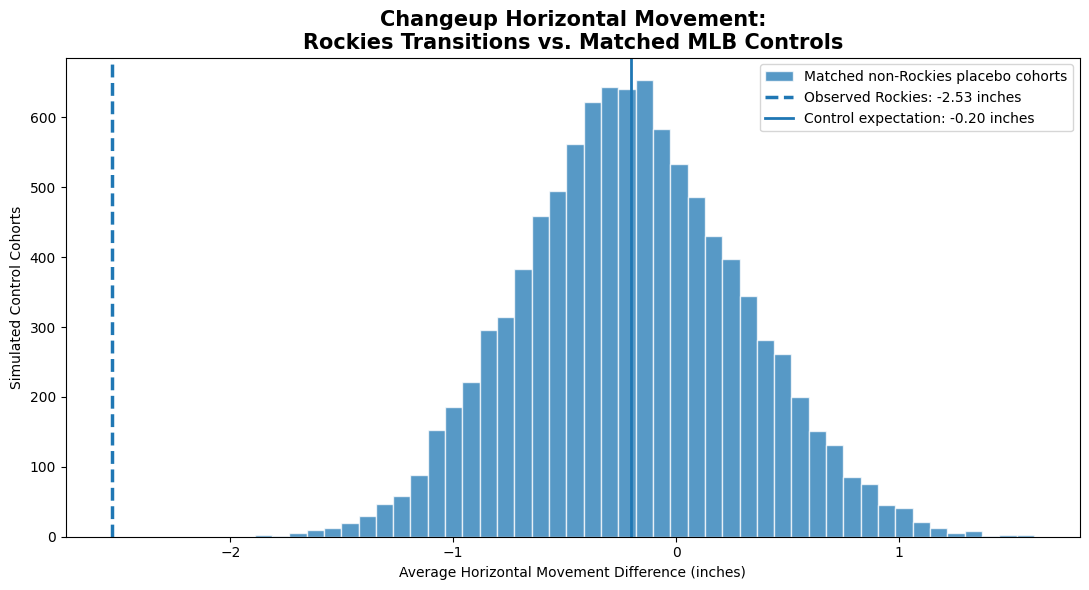


Control analysis saved successfully.


In [16]:
# ============================================================
# STEP 16: CHANGEUP MOVEMENT VS MLB CONTROL GROUP
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)

# ------------------------------------------------------------
# 1. Load our existing data
# ------------------------------------------------------------

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

rockies_roster = pd.read_csv(
    DATA_PATH / "rockies_pitchers_2015_2026.csv"
)

detail = pd.read_csv(
    DATA_PATH / "coors_changeup_cutter_detailed.csv"
)

# Our previously verified 100% Rockies changeup sample
rockies_sample = detail[
    detail["pitch_type"] == "changeup"
].copy()

rockies_sample["horizontal_difference"] = pd.to_numeric(
    rockies_sample["horizontal_difference"],
    errors="raise"
)

# Average repeated transitions at the pitcher level
observed_pitchers = (
    rockies_sample
    .groupby("player_id", as_index=False)
    .agg(
        player_name=("player_name", "first"),
        movement_change=("horizontal_difference", "mean")
    )
)

observed_mean = observed_pitchers["movement_change"].mean()
observed_negative = (
    observed_pitchers["movement_change"] < 0
).sum()

print("OBSERVED ROCKIES RESULTS")
print("Unique pitchers:", len(observed_pitchers))
print("Average movement change:", round(observed_mean, 2))
print(
    "Pitchers with reduced movement:",
    observed_negative, "of", len(observed_pitchers)
)

# ------------------------------------------------------------
# 2. Build a non-Rockies control population
# ------------------------------------------------------------

# Exclude anyone with a Rockies appearance during our period
ever_rockies = set(
    rockies_roster["player_id"].astype(int)
)

controls = master[
    (master["pitch_type"] == "changeup")
    & (~master["player_id"].isin(ever_rockies))
    & (master["player_id"] != 519381)
].copy()

numeric_cols = [
    "pa", "usage_percent", "avg_break_x"
]

for col in numeric_cols:
    controls[col] = pd.to_numeric(
        controls[col],
        errors="coerce"
    )

# Match our original quality thresholds
controls = controls[
    (controls["pa"] >= 100)
    & (controls["usage_percent"] >= 5)
].copy()

controls = controls.dropna(
    subset=["avg_break_x"]
)

# Convert horizontal movement to magnitude
controls["movement"] = controls["avg_break_x"].abs()

# Check uniqueness
assert not controls.duplicated(
    ["player_id", "year"]
).any(), "Duplicate control pitcher-seasons found."

print("\nCONTROL POPULATION")
print("Eligible pitchers:", controls["player_id"].nunique())
print("Eligible pitcher-seasons:", len(controls))

# ------------------------------------------------------------
# 3. Calculate ordinary year-to-year MLB fluctuations
# ------------------------------------------------------------

controls = controls.sort_values(
    ["player_id", "year"]
).copy()

controls["previous_year"] = (
    controls.groupby("player_id")["year"].shift(1)
)

controls["previous_movement"] = (
    controls.groupby("player_id")["movement"].shift(1)
)

controls["year_gap"] = (
    controls["year"] - controls["previous_year"]
)

# Consecutive seasons only
control_pairs = controls[
    controls["year_gap"] == 1
].copy()

# Exclude tracking-system transition
control_pairs = control_pairs[
    ~(
        (control_pairs["previous_year"] == 2019)
        & (control_pairs["year"] == 2020)
    )
].copy()

control_pairs["movement_change"] = (
    control_pairs["movement"]
    - control_pairs["previous_movement"]
)

control_pairs["absolute_change"] = (
    control_pairs["movement_change"].abs()
)

print("\nNORMAL MLB YEAR-TO-YEAR CHANGEUP VARIATION")
print("Consecutive-year comparisons:", len(control_pairs))

print(
    "Median absolute change:",
    round(control_pairs["absolute_change"].median(), 2)
)

print(
    "Mean absolute change:",
    round(control_pairs["absolute_change"].mean(), 2)
)

print(
    "90th percentile absolute change:",
    round(control_pairs["absolute_change"].quantile(0.90), 2)
)

# ------------------------------------------------------------
# 4. Construct calendar-year-matched placebo comparisons
# ------------------------------------------------------------

# Index each control pitcher's seasons and movement magnitudes
control_histories = {
    int(pid): dict(zip(group["year"], group["movement"]))
    for pid, group in controls.groupby("player_id")
}

matched_control_values = {}
matching_summary = []

for rockies_pid, events in rockies_sample.groupby("player_id"):

    rockies_pid = int(rockies_pid)
    placebo_values = []

    # Find control pitchers with all seasons required
    # for this Rockies pitcher's transition(s)
    for control_pid, history in control_histories.items():

        required_years = set(
            events["rockies_year"].astype(int)
        ) | set(
            events["other_year"].astype(int)
        )

        if not required_years.issubset(history):
            continue

        # Orient each placebo comparison exactly like
        # the Rockies-minus-other comparison.
        differences = []

        for event in events.itertuples():

            rockies_year = int(event.rockies_year)
            other_year = int(event.other_year)

            difference = (
                history[rockies_year]
                - history[other_year]
            )

            differences.append(difference)

        # Average when the Rockies pitcher has
        # multiple transitions, just as in Step 15
        placebo_values.append(np.mean(differences))

    if not placebo_values:
        raise ValueError(
            f"No matched controls for Rockies pitcher {rockies_pid}"
        )

    matched_control_values[rockies_pid] = np.array(
        placebo_values
    )

    matching_summary.append({
        "player_id": rockies_pid,
        "player_name": events["player_name"].iloc[0],
        "matched_control_candidates": len(placebo_values),
        "control_mean": np.mean(placebo_values)
    })

matching_df = pd.DataFrame(matching_summary)

print("\nMATCHED CONTROL AVAILABILITY")
display(matching_df)

# ------------------------------------------------------------
# 5. Simulate 10,000 matched control samples
# ------------------------------------------------------------

rng = np.random.default_rng(42)

N_SIMULATIONS = 10000

simulated_columns = []

for pid in observed_pitchers["player_id"]:

    values = matched_control_values[int(pid)]

    simulated_columns.append(
        rng.choice(
            values,
            size=N_SIMULATIONS,
            replace=True
        )
    )

# Each simulated row represents an 11-pitcher
# placebo cohort matched to the Rockies transitions
simulated = np.column_stack(simulated_columns)

simulated_means = simulated.mean(axis=1)

simulated_negative_counts = (
    simulated < 0
).sum(axis=1)

# Fraction of simulated averages as low as the
# observed Rockies average
empirical_p = (
    np.sum(simulated_means <= observed_mean) + 1
) / (N_SIMULATIONS + 1)

direction_p = (
    np.sum(simulated_negative_counts >= observed_negative) + 1
) / (N_SIMULATIONS + 1)

# ------------------------------------------------------------
# 6. Report results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ROCKIES CHANGEUPS VS MATCHED MLB CONTROLS")
print("=" * 60)

print(
    "Rockies average movement difference:",
    round(observed_mean, 2)
)

print(
    "Matched control expected average:",
    round(simulated_means.mean(), 2)
)

print(
    "Control simulation 95% range:",
    np.percentile(simulated_means, [2.5, 97.5]).round(2)
)

print(
    "Rockies minus control expectation:",
    round(observed_mean - simulated_means.mean(), 2)
)

print(
    "Exploratory empirical lower-tail probability:",
    round(empirical_p, 5)
)

print(
    "Exploratory probability of matching directional consistency:",
    round(direction_p, 5)
)

# ------------------------------------------------------------
# 7. Visualize the comparison
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.hist(
    simulated_means,
    bins=45,
    alpha=0.75,
    edgecolor="white",
    label="Matched non-Rockies placebo cohorts"
)

plt.axvline(
    observed_mean,
    linewidth=2.5,
    linestyle="--",
    label=f"Observed Rockies: {observed_mean:.2f} inches"
)

plt.axvline(
    simulated_means.mean(),
    linewidth=2,
    label=f"Control expectation: {simulated_means.mean():.2f} inches"
)

plt.title(
    "Changeup Horizontal Movement:\n"
    "Rockies Transitions vs. Matched MLB Controls",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Horizontal Movement Difference (inches)")
plt.ylabel("Simulated Control Cohorts")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Save outputs
# ------------------------------------------------------------

control_pairs.to_csv(
    DATA_PATH / "mlb_changeup_yearly_variation.csv",
    index=False
)

matching_df.to_csv(
    DATA_PATH / "coors_changeup_matched_controls.csv",
    index=False
)

simulation_summary = pd.DataFrame({
    "simulated_mean": simulated_means,
    "negative_count": simulated_negative_counts
})

simulation_summary.to_csv(
    DATA_PATH / "coors_changeup_control_simulations.csv",
    index=False
)

print("\nControl analysis saved successfully.")

### Step 17 — Test whether the data is available


In [17]:

from pybaseball import statcast_pitcher
import pandas as pd
import numpy as np

# Jon Gray — 2021 Rockies season
pitches = statcast_pitcher(
    start_dt="2021-04-01",
    end_dt="2021-10-03",
    player_id=592351
)

# Regular-season changeups
ch = pitches[
    (pitches["pitch_type"] == "CH")
    & (pitches["game_type"] == "R")
].copy()

ch["pfx_x"] = pd.to_numeric(ch["pfx_x"], errors="coerce")
ch = ch.dropna(subset=["pfx_x"])

# Identify Rockies home vs road games
ch["environment"] = np.select(
    [
        ch["home_team"] == "COL",
        ch["away_team"] == "COL"
    ],
    [
        "Rockies Home",
        "Rockies Road"
    ],
    default="Other"
)

ch = ch[ch["environment"] != "Other"]

# pfx_x is measured in feet; convert to inches
ch["horizontal_inches"] = ch["pfx_x"] * 12

summary = (
    ch.groupby("environment")
    .agg(
        pitches=("horizontal_inches", "size"),
        avg_signed_movement=("horizontal_inches", "mean")
    )
    .reset_index()
)

summary["movement_magnitude"] = (
    summary["avg_signed_movement"].abs()
)

print("JON GRAY — 2021 CHANGEUP MOVEMENT")
display(summary.round(2))

if set(summary["environment"]) == {
    "Rockies Home", "Rockies Road"
}:
    home = summary.set_index("environment").loc[
        "Rockies Home", "movement_magnitude"
    ]
    road = summary.set_index("environment").loc[
        "Rockies Road", "movement_magnitude"
    ]

    print(
        "\nHome minus road movement magnitude:",
        round(home - road, 2),
        "inches"
    )

Gathering Player Data
JON GRAY — 2021 CHANGEUP MOVEMENT


,environment,pitches,avg_signed_movement,movement_magnitude
0,Rockies Home,113,-10.1,10.1
1,Rockies Road,91,-13.6,13.6



Home minus road movement magnitude: -3.5 inches


### Step 18 — Make sure Jon Gray's result isn't driven by a few games


In [18]:
# ============================================================
# STEP 18: JON GRAY HOME/ROAD GAME-LEVEL ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)

df = ch.copy()

for col in ["horizontal_inches", "release_speed",
            "release_spin_rate"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Home/road pitch characteristics
summary = (
    df.groupby("environment")
    .agg(
        games=("game_pk", "nunique"),
        pitches=("horizontal_inches", "size"),
        signed_movement=("horizontal_inches", "mean"),
        velocity=("release_speed", "mean"),
        spin_rpm=("release_spin_rate", "mean")
    )
    .reset_index()
)

summary["movement_magnitude"] = (
    summary["signed_movement"].abs()
)

print("JON GRAY — HOME VS ROAD PITCH CHARACTERISTICS")
display(summary.round(2))

# Aggregate pitch movement within each game
games = (
    df.groupby(["environment", "game_pk"])
    .agg(
        pitch_count=("horizontal_inches", "size"),
        movement_sum=("horizontal_inches", "sum")
    )
    .reset_index()
)

home = games[games["environment"] == "Rockies Home"]
road = games[games["environment"] == "Rockies Road"]

if home.empty or road.empty:
    raise ValueError("Both home and road games are required.")

# Cluster bootstrap: sample entire games with replacement
rng = np.random.default_rng(42)
B = 10000

def bootstrap_game_means(group):
    n = len(group)
    indices = rng.integers(0, n, size=(B, n))

    sums = group["movement_sum"].to_numpy()
    counts = group["pitch_count"].to_numpy()

    return (
        sums[indices].sum(axis=1)
        / counts[indices].sum(axis=1)
    )

home_boot = bootstrap_game_means(home)
road_boot = bootstrap_game_means(road)

# Same magnitude definition used in our original comparison
boot_difference = (
    np.abs(home_boot) - np.abs(road_boot)
)

lower, upper = np.percentile(
    boot_difference, [2.5, 97.5]
)

actual = (
    abs(df.loc[df["environment"] == "Rockies Home",
               "horizontal_inches"].mean())
    -
    abs(df.loc[df["environment"] == "Rockies Road",
               "horizontal_inches"].mean())
)

print("\nGAME-LEVEL BOOTSTRAP RESULTS")
print("Home games:", len(home))
print("Road games:", len(road))
print("Observed home minus road:", round(actual, 2), "inches")
print(
    "95% bootstrap interval:",
    round(lower, 2), "to", round(upper, 2), "inches"
)

print(
    "Bootstrap percentage with less movement at home:",
    round(100 * (boot_difference < 0).mean(), 2), "%"
)

# Save result
summary.to_csv(
    DATA_PATH / "jon_gray_2021_home_road_changeup.csv",
    index=False
)

JON GRAY — HOME VS ROAD PITCH CHARACTERISTICS


,environment,games,pitches,signed_movement,velocity,spin_rpm,movement_magnitude
0,Rockies Home,14,113,-10.1,87.49,1441.39,10.1
1,Rockies Road,14,91,-13.6,87.73,1476.45,13.6



GAME-LEVEL BOOTSTRAP RESULTS
Home games: 14
Road games: 14
Observed home minus road: -3.5 inches
95% bootstrap interval: -4.8 to -2.12 inches
Bootstrap percentage with less movement at home: 100.0 %


### Step 19 — Replicate this across our 11 changeup pitchers


In [19]:
# ============================================================
# STEP 19: HOME VS ROAD CHANGEUP MOVEMENT — 11 PITCHERS
# ============================================================

import pandas as pd
import numpy as np
import time
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path(PROJECT_DIR)
CACHE_DIR = DATA_PATH / "Statcast_Changeups"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Our previously verified 100% Rockies transitions
detail = pd.read_csv(
    DATA_PATH / "coors_changeup_cutter_detailed.csv"
)

# Unique pitcher-season combinations
pitchers = (
    detail[detail["pitch_type"] == "changeup"]
    [["player_id", "player_name", "rockies_year"]]
    .drop_duplicates()
    .sort_values(["rockies_year", "player_name"])
)

print("Unique pitcher-seasons to check:", len(pitchers))

results = []
failures = []

for row in pitchers.itertuples(index=False):

    pid = int(row.player_id)
    year = int(row.rockies_year)
    name = row.player_name

    print(f"\nChecking {name} — {year}")

    cache_file = CACHE_DIR / f"{pid}_{year}_CH.csv"

    try:
        if cache_file.exists():
            ch = pd.read_csv(cache_file)

        else:
            raw = statcast_pitcher(
                start_dt=f"{year}-03-01",
                end_dt=f"{year}-11-15",
                player_id=pid
            )

            if raw is None or raw.empty:
                raise ValueError("No Statcast pitches returned")

            # Regular-season changeups only
            ch = raw[
                (raw["pitch_type"] == "CH")
                & (raw["game_type"] == "R")
            ][[
                "game_pk",
                "game_date",
                "home_team",
                "away_team",
                "pfx_x",
                "release_speed",
                "release_spin_rate"
            ]].copy()

            ch.to_csv(cache_file, index=False)
            time.sleep(1)

        if ch.empty:
            raise ValueError("No changeups found")

        # Convert Statcast movement from feet to inches
        ch["horizontal_inches"] = (
            pd.to_numeric(ch["pfx_x"], errors="coerce") * 12
        )

        ch = ch.dropna(subset=["horizontal_inches"])

        # Identify Colorado home and road appearances
        ch["environment"] = np.select(
            [
                ch["home_team"] == "COL",
                ch["away_team"] == "COL"
            ],
            [
                "Home",
                "Road"
            ],
            default="Other"
        )

        ch = ch[ch["environment"].isin(["Home", "Road"])]

        summary = (
            ch.groupby("environment")
            .agg(
                pitches=("horizontal_inches", "size"),
                games=("game_pk", "nunique"),
                signed_movement=("horizontal_inches", "mean")
            )
        )

        if not {"Home", "Road"}.issubset(summary.index):
            raise ValueError("Missing home or road observations")

        home = summary.loc["Home"]
        road = summary.loc["Road"]

        home_movement = abs(home["signed_movement"])
        road_movement = abs(road["signed_movement"])

        difference = home_movement - road_movement

        # Flag low-exposure comparisons without discarding them
        sufficient_sample = (
            home["pitches"] >= 20
            and road["pitches"] >= 20
            and home["games"] >= 3
            and road["games"] >= 3
        )

        results.append({
            "player_id": pid,
            "player_name": name,
            "year": year,
            "home_games": int(home["games"]),
            "road_games": int(road["games"]),
            "home_pitches": int(home["pitches"]),
            "road_pitches": int(road["pitches"]),
            "home_movement": home_movement,
            "road_movement": road_movement,
            "home_minus_road": difference,
            "sufficient_sample": sufficient_sample
        })

    except Exception as e:
        failures.append({
            "player_name": name,
            "year": year,
            "error": str(e)
        })
        print("Unable to calculate:", e)

# ============================================================
# RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("ROCKIES CHANGEUP HOME VS ROAD ANALYSIS")
print("=" * 65)

print("Pitcher-seasons requested:", len(pitchers))
print("Successful comparisons:", len(results))
print("Failed comparisons:", len(failures))

if not results_df.empty:

    display(
        results_df.sort_values("home_minus_road").round(2)
    )

    valid = results_df[
        results_df["sufficient_sample"]
    ].copy()

    print("\nCOMPARISONS WITH ADEQUATE PITCH/GAME COUNTS")
    print("Qualifying pitchers:", len(valid))

    if not valid.empty:
        print(
            "Average home-road difference:",
            round(valid["home_minus_road"].mean(), 2),
            "inches"
        )

        print(
            "Median home-road difference:",
            round(valid["home_minus_road"].median(), 2),
            "inches"
        )

        print(
            "Pitchers with less movement at home:",
            int((valid["home_minus_road"] < 0).sum()),
            "of",
            len(valid)
        )

    results_df.to_csv(
        DATA_PATH / "coors_changeups_home_road_11_pitchers.csv",
        index=False
    )

if failures:
    print("\nFAILED COMPARISONS")
    display(pd.DataFrame(failures))

Unique pitcher-seasons to check: 11

Checking Kahnle, Tommy — 2015

Checking Bergman, Christian — 2016

Checking Butler, Eddie — 2016

Checking Almonte, Yency — 2021

Checking Gomber, Austin — 2021

Checking Gray, Jon — 2021

Checking Estévez, Carlos — 2022

Checking Suter, Brent — 2023

Checking Molina, Anthony — 2025

Checking Bernardino, Brennan — 2026

Checking Quintana, Jose — 2026

ROCKIES CHANGEUP HOME VS ROAD ANALYSIS
Pitcher-seasons requested: 11
Successful comparisons: 11
Failed comparisons: 0


,player_id,player_name,year,home_games,road_games,home_pitches,road_pitches,home_movement,road_movement,home_minus_road,sufficient_sample
2,572750,"Butler, Eddie",2016,7,7,47,28,7.35,12.80,-5.45,True
1,548357,"Bergman, Christian",2016,6,8,38,38,9.92,14.01,-4.09,True
3,622075,"Almonte, Yency",2021,19,15,53,36,12.34,16.04,-3.70,True
8,683627,"Molina, Anthony",2025,11,6,72,38,12.37,16.03,-3.66,True
5,592351,"Gray, Jon",2021,14,14,113,91,10.10,13.60,-3.50,True
10,500779,"Quintana, Jose",2026,5,6,85,80,11.79,14.83,-3.04,True
9,657514,"Bernardino, Brennan",2026,24,18,47,27,11.39,13.82,-2.43,True
4,596295,"Gomber, Austin",2021,9,14,155,205,8.56,10.98,-2.42,True
7,608718,"Suter, Brent",2023,26,29,163,156,7.64,9.45,-1.81,True
0,592454,"Kahnle, Tommy",2015,18,17,106,158,11.04,12.49,-1.44,True



COMPARISONS WITH ADEQUATE PITCH/GAME COUNTS
Qualifying pitchers: 11
Average home-road difference: -2.98 inches
Median home-road difference: -3.04 inches
Pitchers with less movement at home: 11 of 11


### Step 20 — Test a new group of Rockies pitchers


In [20]:
# ============================================================
# STEP 20: INDEPENDENT 2024 ROCKIES CHANGEUP VALIDATION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path(PROJECT_DIR)
CACHE = DATA_PATH / "Statcast_2024_Validation"
CACHE.mkdir(parents=True, exist_ok=True)

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

for col in ["year", "pa", "usage_percent"]:
    master[col] = pd.to_numeric(master[col], errors="coerce")

# Choose eligible pitchers BEFORE examining home-road movement
eligible = (
    master[
        (master["year"] == 2024)
        & (master["rockies"].astype(str).str.upper() == "Y")
        & (master["pitch_type"] == "changeup")
        & (master["pa"] >= 100)
        & (master["usage_percent"] >= 5)
    ][["player_id", "player_name"]]
    .drop_duplicates("player_id")
    .sort_values("player_name")
)

print("2024 eligible Rockies changeup pitchers:", len(eligible))

results = []
failures = []

for row in eligible.itertuples(index=False):

    pid = int(row.player_id)
    name = row.player_name

    print(f"Checking {name}")

    cache_file = CACHE / f"{pid}_2024_COL_CH.csv"

    try:
        if cache_file.exists():
            ch = pd.read_csv(cache_file)
        else:
            raw = statcast_pitcher(
                start_dt="2024-03-01",
                end_dt="2024-10-05",
                player_id=pid
            )

            if raw is None or raw.empty:
                raise ValueError("No Statcast records")

            raw = raw[
                (raw["game_type"] == "R")
                & (raw["pitch_type"] == "CH")
            ].copy()

            # Identify the pitcher's actual team:
            # Top inning = home team pitching
            # Bottom inning = away team pitching
            half = raw["inning_topbot"].astype(str).str.lower()

            top = half.str.startswith("top")
            bottom = half.str.startswith("bot")

            raw = raw.loc[top | bottom].copy()

            top = raw["inning_topbot"].str.lower().str.startswith("top")

            raw["pitching_team"] = np.where(
                top,
                raw["home_team"],
                raw["away_team"]
            )

            # Keep only pitches actually thrown for Colorado
            ch = raw[
                raw["pitching_team"] == "COL"
            ].copy()

            ch["environment"] = np.where(
                ch["home_team"] == "COL",
                "Home",
                "Road"
            )

            ch = ch[
                ["game_pk", "environment", "pfx_x",
                 "release_speed", "release_spin_rate"]
            ].copy()

            ch.to_csv(cache_file, index=False)

        ch["movement_inches"] = (
            pd.to_numeric(ch["pfx_x"], errors="coerce") * 12
        )

        ch = ch.dropna(subset=["movement_inches"])

        summary = (
            ch.groupby("environment")
            .agg(
                pitches=("movement_inches", "size"),
                games=("game_pk", "nunique"),
                signed_movement=("movement_inches", "mean")
            )
        )

        if not {"Home", "Road"}.issubset(summary.index):
            raise ValueError("Missing home or road sample")

        home = summary.loc["Home"]
        road = summary.loc["Road"]

        sufficient = (
            home["pitches"] >= 20
            and road["pitches"] >= 20
            and home["games"] >= 3
            and road["games"] >= 3
        )

        home_mag = abs(home["signed_movement"])
        road_mag = abs(road["signed_movement"])

        results.append({
            "player_name": name,
            "player_id": pid,
            "home_games": int(home["games"]),
            "road_games": int(road["games"]),
            "home_pitches": int(home["pitches"]),
            "road_pitches": int(road["pitches"]),
            "home_movement": home_mag,
            "road_movement": road_mag,
            "difference": home_mag - road_mag,
            "pct_change": (
                100 * (home_mag - road_mag) / road_mag
                if road_mag > 0 else np.nan
            ),
            "direction_reversed": (
                home["signed_movement"]
                * road["signed_movement"] < 0
            ),
            "sufficient_sample": sufficient
        })

    except Exception as exc:
        failures.append({
            "player_name": name,
            "error": str(exc)
        })

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("2024 ROCKIES CHANGEUP VALIDATION")
print("=" * 60)

print("Eligible pitchers:", len(eligible))
print("Successfully retrieved:", len(results))
print("Retrieval failures:", len(failures))

if not results_df.empty:

    display(
        results_df.sort_values("difference").round(2)
    )

    valid = results_df[
        results_df["sufficient_sample"]
    ].copy()

    print("\nQUALIFYING HOME-ROAD COMPARISONS")
    print("Pitchers:", len(valid))

    if not valid.empty:

        print(
            "Average home-road difference:",
            round(valid["difference"].mean(), 2),
            "inches"
        )

        print(
            "Median home-road difference:",
            round(valid["difference"].median(), 2),
            "inches"
        )

        print(
            "Less movement at home:",
            int((valid["difference"] < 0).sum()),
            "of", len(valid)
        )

        print(
            "Average percentage change:",
            round(valid["pct_change"].mean(), 2), "%"
        )

        print(
            "Movement-direction reversals:",
            int(valid["direction_reversed"].sum())
        )

    results_df.to_csv(
        DATA_PATH / "coors_2024_changeup_validation.csv",
        index=False
    )

if failures:
    print("\nRETRIEVAL FAILURES")
    display(pd.DataFrame(failures))

2024 eligible Rockies changeup pitchers: 11
Checking Beeks, Jalen
Checking Blach, Ty
Checking Chivilli, Angel
Checking Feltner, Ryan
Checking Freeland, Kyle
Checking Gomber, Austin
Checking Gordon, Tanner
Checking Hudson, Dakota
Checking Lambert, Peter
Checking Molina, Anthony
Checking Vodnik, Victor

2024 ROCKIES CHANGEUP VALIDATION
Eligible pitchers: 11
Successfully retrieved: 11
Retrieval failures: 0


,player_name,player_id,home_games,road_games,home_pitches,road_pitches,home_movement,road_movement,difference,pct_change,direction_reversed,sufficient_sample
1,"Blach, Ty",621389,13,7,206,72,12.69,17.60,-4.92,-27.94,False,True
7,"Hudson, Dakota",641712,10,8,94,58,10.83,15.28,-4.45,-29.13,False,True
8,"Lambert, Peter",663567,11,16,104,156,9.47,13.34,-3.87,-29.04,False,True
0,"Beeks, Jalen",656222,22,21,75,138,12.31,16.14,-3.83,-23.74,False,True
10,"Vodnik, Victor",680767,30,29,111,111,11.35,14.84,-3.48,-23.48,False,True
4,"Freeland, Kyle",607536,10,11,83,123,10.25,13.33,-3.08,-23.12,False,True
5,"Gomber, Austin",596295,14,16,240,298,8.39,11.44,-3.04,-26.60,False,True
2,"Chivilli, Angel",683409,17,12,133,73,9.66,12.70,-3.03,-23.89,False,True
9,"Molina, Anthony",683627,16,16,115,120,11.83,14.79,-2.96,-20.04,False,True
6,"Gordon, Tanner",685299,2,6,37,79,12.40,14.73,-2.32,-15.78,False,False



QUALIFYING HOME-ROAD COMPARISONS
Pitchers: 10
Average home-road difference: -3.36 inches
Median home-road difference: -3.28 inches
Less movement at home: 10 of 10
Average percentage change: -24.23 %
Movement-direction reversals: 0


### Audit 3 Statistical Confidence interval


In [24]:
# ============================================================
# AUDIT 3 — FINAL CHANGEUP CONFIDENCE INTERVAL
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)

df = pd.read_csv(
    DATA_PATH / "coors_2024_changeup_validation.csv"
)

# Only qualifying pitchers
valid = df[
    df["sufficient_sample"]
    .astype(str).str.lower().eq("true")
].copy()

assert not valid["player_id"].duplicated().any()

values = valid["difference"].dropna().to_numpy()

# Bootstrap across pitchers, not individual pitches
rng = np.random.default_rng(42)

samples = rng.choice(
    values,
    size=(20000, len(values)),
    replace=True
)

bootstrap_means = samples.mean(axis=1)

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print("=" * 55)
print("FINAL 2024 CHANGEUP STATISTICAL VALIDATION")
print("=" * 55)

print("Unique pitchers:", len(values))
print("Mean difference:", round(values.mean(), 2))
print("Median difference:", round(np.median(values), 2))
print("Pitchers with less movement at home:", (values < 0).sum())

print(
    "95% pitcher-level bootstrap CI:",
    round(ci_lower, 2),
    "to",
    round(ci_upper, 2),
    "inches"
)

summary = pd.DataFrame([{
    "pitchers": len(values),
    "mean_difference": values.mean(),
    "median_difference": np.median(values),
    "ci_lower": ci_lower,
    "ci_upper": ci_upper,
    "negative_count": int((values < 0).sum())
}])

summary.to_csv(
    DATA_PATH / "coors_changeup_final_statistics.csv",
    index=False
)

print("\nFinal statistics saved.")

FINAL 2024 CHANGEUP STATISTICAL VALIDATION
Unique pitchers: 10
Mean difference: -3.36
Median difference: -3.28
Pitchers with less movement at home: 10
95% pitcher-level bootstrap CI: -3.95 to -2.68 inches

Final statistics saved.
